# Mode-monitor width versus power normalization

A `td.ModeMonitor` reports the amplitude `a` of the mode it computes **on its own plane**, and
the guided power is `|a|²`. That number is the waveguide transmission only if the monitor
window contains the mode. On a hybrid SiN/TFLN stack the guided mode has evanescent tails in
the slab, so a monitor narrower than the slab can under-read the power by about 10 % even
though nothing in the guide is lossy.

This notebook measures the same output plane twice — with a 2 µm and an 8 µm monitor — in a
single simulation, and shows where the missing power sits.

In the run below the 8 µm monitor reads `0.9315 / 0.9310 / 0.9305`, matching the project's straight-guide
validation to within 0.1 %, and `n_g = 2.186` matches it as well. The 2 µm window on the same plane reads
`0.796`, 14 % low. The full-core layout, with a 26 µm slab and 2 µm lane windows,
measured `0.826` against the same `0.930`; the size of the deficit depends on the layout, its
sign does not.

*Requires `tidy3d >= 2.10`.*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tidy3d as td
import tidy3d.web as web

print("tidy3d", td.__version__)

tidy3d 2.12.2


## The stack

| layer | thickness | refractive index |
|---|---|---|
| SiN core | 0.300 µm | 1.980 |
| SiO2 gap | 0.050 µm | 1.444 |
| TFLN slab | 0.300 µm | 2.211 ordinary / 2.138 extraordinary |

The SiN strip is 0.800 µm wide and 21 µm long; the TFLN slab beneath it is 8 µm wide and runs
the full 24 µm domain, through the PML in `x`, so the guided mode never meets a slab facet. The
mode's tails therefore run through slab material far beyond the 0.8 µm core — exactly the
region a narrow monitor window cuts off.

In [2]:
WL = 1.55                                        # centre wavelength, um
FREQS = td.C_0 / np.array([1.545, 1.550, 1.555])   # three comb lines, Hz
F0 = float(np.mean(FREQS))

T_SIN, W_SIN = 0.300, 0.800                       # SiN core, um
T_GAP, T_TFLN = 0.050, 0.300                      # SiO2 gap and TFLN slab, um
N_SIO2, N_SIN = 1.444, 1.980
N_TFLN_O, N_TFLN_E = 2.211, 2.138                 # X-cut: ordinary in-plane, extraordinary out

sio2 = td.Medium(permittivity=N_SIO2**2, name="SiO2")
sin = td.Medium(permittivity=N_SIN**2, name="SiN")
tfln = td.AnisotropicMedium(
    xx=td.Medium(permittivity=N_TFLN_O**2),
    yy=td.Medium(permittivity=N_TFLN_O**2),
    zz=td.Medium(permittivity=N_TFLN_E**2),
    name="TFLN",
)

GUIDE_HALF = 10.5                                 # SiN guide spans -10.5 .. 10.5 um
SLAB_HALF = 12.0                                  # slab runs through the PML, so no facet
SLAB_WIDTH = 8.0                                  # TFLN slab width, um
DOMAIN_Y = SLAB_WIDTH + 2.0                       # 1 um of SiO2 either side of the slab

# The slab must extend past the PML in x. A slab that stops 0.5 um after the output
# monitor reflects a few percent of the guided mode and puts a standing wave on the
# monitor plane, which lowers |a|^2 by several percent all by itself.
structures = [
    td.Structure(
        geometry=td.Box(center=(0, 0, 0), size=(2 * GUIDE_HALF, W_SIN, T_SIN)),
        medium=sin,
        name="SiN",
    ),
    td.Structure(
        geometry=td.Box(
            center=(0, 0, T_SIN / 2 + T_GAP + T_TFLN / 2),
            size=(2 * SLAB_HALF, SLAB_WIDTH, T_TFLN),
        ),
        medium=tfln,
        name="TFLN",
    ),
]
print(f"guide {2 * GUIDE_HALF:g} um long, slab {2 * SLAB_HALF:g} um long and {SLAB_WIDTH:g} um wide")

guide 21 um long, slab 24 um long and 8 um wide


## One plane, two monitor widths

Both output monitors sit at the same `x`, so they see the identical field. Only the width of
the plane they project onto differs. A `FieldMonitor` covering the full 8 µm is added so the
tail power can be measured directly.

The source and monitors are the ones used for the full-core verification runs, so the numbers
transfer: a 3D FDTD of a straight guide, 500 optical periods, PML on all sides.

In [3]:
X_SOURCE, X_MONITOR = -10.0, 10.0
MONITOR_WIDTHS = {"2um": 2.0, "8um": 8.0}

source = td.ModeSource(
    center=(X_SOURCE, 0.0, 0.0),
    size=(0.0, 2.5, T_SIN + 1.5),
    source_time=td.GaussianPulse(freq0=F0, fwidth=0.15 * F0),
    direction="+",
    mode_spec=td.ModeSpec(num_modes=1),
    name="input",
)

outputs = [
    td.ModeMonitor(
        center=(X_MONITOR, 0.0, 0.0),
        size=(0.0, width, T_SIN + 1.5),
        freqs=FREQS,
        mode_spec=td.ModeSpec(num_modes=1),
        name=f"out_{label}",
    )
    for label, width in MONITOR_WIDTHS.items()
]
reflection = td.ModeMonitor(
    center=(X_SOURCE - 0.4, 0.0, 0.0),
    size=(0.0, SLAB_WIDTH, T_SIN + 1.5),
    freqs=FREQS,
    mode_spec=td.ModeSpec(num_modes=1),
    name="refl",
)
field = td.FieldMonitor(
    center=(X_MONITOR, 0.0, 0.0),
    size=(0.0, SLAB_WIDTH, 2.8),
    freqs=[float(FREQS[1])],
    name="field",
)
print([monitor.name for monitor in outputs + [reflection, field]])

['out_2um', 'out_8um', 'refl', 'field']


## Simulation

The domain is 24 µm long and 10 µm wide. Across `y` the 8 µm slab edge sits 1 µm inside the
PML — more than half a wavelength, so the solver raises no proximity warning. Along `x` the
slab deliberately passes through the PML, for the reason given at the end of this section.
`GridSpec.auto` at 25 steps per wavelength
resolves the 300 nm core and the 300 nm slab. The run time is 500 periods of the centre
frequency, long enough for the pulse to clear the 21 µm guide; the solver then shuts off early
at about a tenth of the time steps.

Tidy3D estimates about half a FlexCredit for this simulation, and bills less because of that
early shutoff.


Tidy3D prints a `Structure extrusion through PML boundaries` warning for the slab, and it is
expected here: the slab is a box that deliberately runs through the PML in `x`, so the guided
mode never meets a slab facet. Stopping the slab 0.5 µm past the output monitor instead
reflected 3.4e-2 of the power and read 0.868 where this construction reads 0.930.


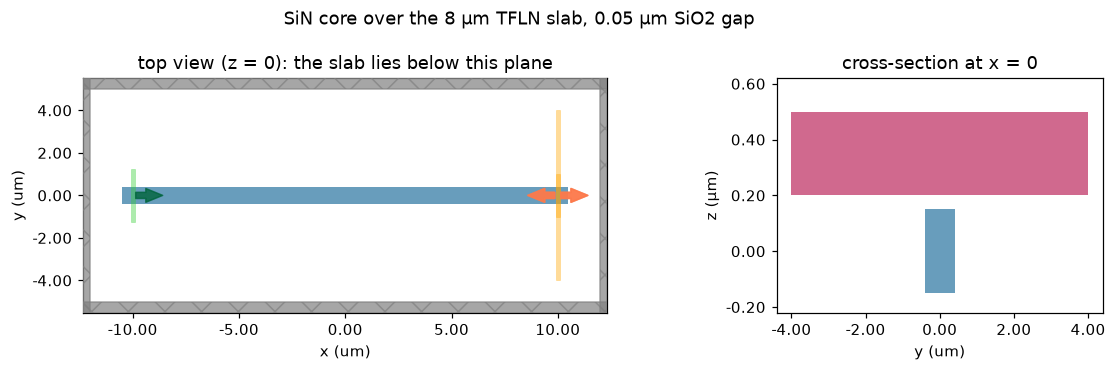

In [4]:
sim = td.Simulation(
    size=(2 * (GUIDE_HALF + 1.5), DOMAIN_Y, 2.8),
    run_time=500 / F0,
    grid_spec=td.GridSpec.auto(min_steps_per_wvl=25, wavelength=WL),
    structures=structures,
    sources=[source],
    monitors=outputs + [reflection, field],
    medium=sio2,
    boundary_spec=td.BoundarySpec.all_sides(boundary=td.PML()),
    plot_length_units="um",
)

fig, (ax_top, ax_side) = plt.subplots(1, 2, figsize=(10, 4.0), gridspec_kw={"width_ratios": [2.0, 1]})
sim.plot(z=0.0, ax=ax_top)
ax_top.set_title("top view (z = 0): the slab is below this plane")
sim.plot(x=0.0, ax=ax_side)
ax_side.set_title("cross-section at x = 0")
ax_side.set_xlim(-4.6, 4.6)
ax_side.set_ylim(-0.45, 0.85)
fig.suptitle("SiN core over the 8 µm TFLN slab (0.05 µm SiO2 gap)")
fig.tight_layout()
plt.show()

In [5]:
sim_data = web.run(
    sim,
    task_name="mode_monitor_width_normalization",
    path="mode_monitor_width.hdf5",
)

14:05:53 Eastern Standard Time Created task 'mode_monitor_width_normalization'  
                               with resource_id                                 
                               'fdve-ab1b6b69-cb5b-4e0d-ae77-53cf9088316e' and  
                               task_type 'FDTD'.                                
                               View task using web UI at                        
                               'https://tidy3d.simulation.cloud/workbench?taskId
                               =fdve-ab1b6b69-cb5b-4e0d-ae77-53cf9088316e'.     
                               Task folder: 'default'.                          
↑ simulation.hdf5.gz ------------------------- 100.0% • 1.8/1.8 kB • ? • 0:00:00
14:05:56 Eastern Standard Time Estimated FlexCredit cost: 0.505. This assumes   
                               the FDTD solver runs for the full simulation     
                               time; if early shutoff is reached, the billed    
                            

## Guided power at each comb line

`ModeMonitor.amps` is normalised so that `|a|²` is the power in that mode, in the same units
as the source. The two columns come from the same field data; the third is their ratio.

In [6]:
powers = {}
for label in MONITOR_WIDTHS:
    amps = sim_data[f"out_{label}"].amps.sel(direction="+", mode_index=0)
    powers[label] = np.abs(amps.values) ** 2

header = f"{'line (nm)':>10s}" + "".join(f"{label:>12s}" for label in MONITOR_WIDTHS)
print(header + f"{'2um/8um':>10s}")
for index, wavelength in enumerate(1e3 * td.C_0 / FREQS):
    values = [powers[label][index] for label in MONITOR_WIDTHS]
    print(f"{wavelength:10.0f}" + "".join(f"{value:12.4f}" for value in values) + f"{values[0] / values[1]:10.3f}")

print()
print(f"mean |a|^2, 2 um monitor: {np.mean(powers['2um']):.4f}")
print(f"mean |a|^2, 8 um monitor: {np.mean(powers['8um']):.4f}")

 line (nm)         2um         8um   2um/8um
      1545      0.7983      0.9315     0.857
      1550      0.7965      0.9310     0.855
      1555      0.7946      0.9305     0.854

mean |a|^2, 2 um monitor: 0.7965
mean |a|^2, 8 um monitor: 0.9310


## Where the missing power is

Integrating `|E_y|²` over the field monitor gives the transverse profile. The shaded band is
the 2 µm window. 18.0 % of the transverse `|Ey|²` sits outside it, which is the size of
the power deficit the narrow monitor reports: the missing power is the tail the window cannot
contain.

fraction of the transverse |Ey|^2 outside |y| <= 1 um: 17.963%


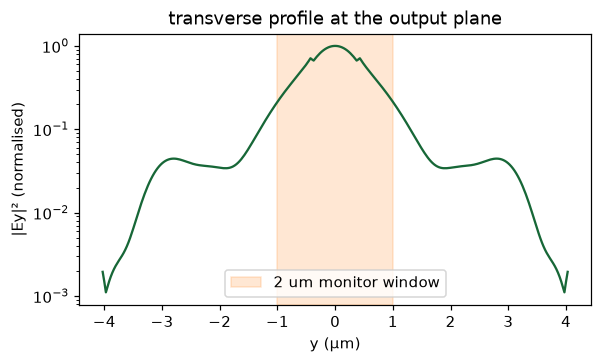

In [7]:
ey2 = np.abs(sim_data["field"].Ey.isel(f=0).squeeze(drop=True)) ** 2
profile = ey2
for dim in list(profile.dims):
    if dim != "y":
        profile = profile.sum(dim)

y = profile.y.values
values = profile.values
inside = np.abs(y) <= 1.0
outside_fraction = 1.0 - values[inside].sum() / values.sum()
print(f"fraction of the transverse |Ey|^2 outside |y| <= 1 um: {outside_fraction:.3%}")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.semilogy(y, values / values.max(), color="C0")
ax.axvspan(-1.0, 1.0, color="C1", alpha=0.18, label="2 um monitor window")
ax.set_xlabel("y (µm)")
ax.set_ylabel("|Ey|² (normalised)")
ax.set_title("transverse profile at the output plane")
ax.legend()
plt.show()

## Group index from the phase slope

With Tidy3D's `e^{-iωt}` convention a forward wave carries `e^{+ikx}`, so
`n_g = +c · dφ/dω / L`, with `L` the source-to-monitor distance (20 µm), not the 21 µm physical
guide length. The absolute phase is arbitrary; the slope is not.

source-to-monitor distance L = 20 um
dphi/domega = 1.4586e-13 s
n_g = 2.186


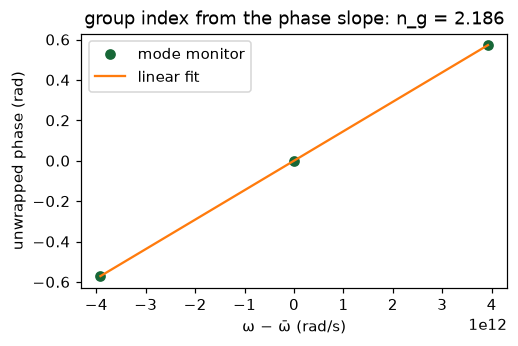

In [8]:
amps8 = sim_data["out_8um"].amps.sel(direction="+", mode_index=0)
phase = np.unwrap(np.angle(amps8.values))
omega = 2 * np.pi * FREQS
offset = omega - omega.mean()
slope, intercept = np.polyfit(offset, phase - phase.mean(), 1)
L = X_MONITOR - X_SOURCE
ng = td.C_0 * slope / L
print(f"source-to-monitor distance L = {L:g} um")
print(f"dphi/domega = {slope:.4e} s")
print(f"n_g = {ng:.3f}")

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(offset, phase - phase.mean(), "o", label="mode monitor")
ax.plot(offset, slope * offset + intercept, "-", label="linear fit")
ax.set_xlabel("ω − ω̄ (rad/s)")
ax.set_ylabel("unwrapped phase (rad)")
ax.set_title(f"group index from the phase slope: n_g = {ng:.3f}")
ax.legend()
plt.show()

## Back-reflection

The reflection monitor sits 0.4 µm before the source plane and looks backwards. An uncoated
facet reflects roughly 1–2 % (−18 dB), so a few 1e-4 in power is the expected order; a value
comparable to the forward power would mean the direction label is wrong.

In [9]:
refl = np.abs(sim_data["refl"].amps.sel(direction="-", mode_index=0).values) ** 2
print("reflection |a|^2 per line:", np.round(refl, 6))
print(f"back-reflection relative to the 8 um output: {np.mean(refl) / np.mean(powers['8um']):.2e}")

reflection |a|^2 per line: [0.000247 0.000194 0.000159]
back-reflection relative to the 8 um output: 2.15e-04


## What to take away

- A `ModeMonitor` measures the mode **it** computes on **its** plane. On a stack with a slab
  wider than the core, a monitor narrower than the slab   under-reads the guided power — by 14 % here
  and 11 % on the full-core layout — with no propagation loss involved.
- Size the monitor wider than the slab (this stack uses 8 µm for the 2.0 µm lane pitch of the
  full core, where neighbouring lanes must stay out of the window), and compare monitor widths
  before trusting an absolute `|a|²`.
- Group index needs the source-to-monitor distance, not the guide length, and an unwrapped
  phase over at least three frequencies.
- The same source and monitor construction is used for the four full-core verification runs in
  the project this notebook comes from, so the normalization carries over.

*Notebook prepared for the Flexcompute community library. The stack values are generic
SiN/TFLN indices, not foundry data.*